In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
def make_symbols(mod, n, rng):
    if mod == "BPSK":
        pts = np.array([1, -1], dtype=complex)
    elif mod == "QPSK":
        pts = np.array([1+1j, -1+1j, -1-1j, 1-1j])
    elif mod == "16QAM":
        lv = np.array([-3, -1, 1, 3])
        pts = (lv[:, None] + 1j * lv[None, :]).ravel()
    else:
        raise ValueError(mod)
    pts = pts / np.sqrt(np.mean(np.abs(pts)**2))
    return rng.choice(pts, n)

In [6]:
def apply_device(x, eps, phi, alpha3):
    k1 = (1 + (1 + eps) * np.exp(-1j * phi)) / 2
    k2 = (1 - (1 + eps) * np.exp(1j * phi)) / 2
    x_iq = k1 * x + k2 * np.conj(x)
    return x_iq + alpha3 * np.abs(x_iq)**2 * x_iq

In [7]:
def add_noise(y, snr_db, rng):
    p_noise = np.mean(np.abs(y)**2) / 10**(snr_db / 10)
    noise = np.sqrt(p_noise / 2) * (rng.standard_normal(len(y))
                                    + 1j * rng.standard_normal(len(y)))
    return y + noise

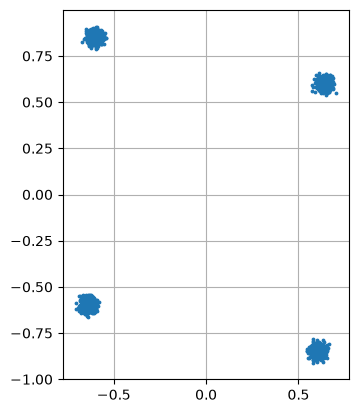

In [8]:
rng = np.random.default_rng(0)
x = make_symbols("QPSK", 2000, rng)
y = add_noise(apply_device(x, eps=0.2, phi=0.2, alpha3=-0.1), 30, rng)
plt.scatter(y.real, y.imag, s=3)
plt.gca().set_aspect("equal"); plt.grid(); plt.show()

In [9]:
def make_devices(n_devices, rng):
    devices = []
    for _ in range(n_devices):
        devices.append({
            "eps": rng.uniform(-0.05, 0.05),
            "phi": np.deg2rad(rng.uniform(-3, 3)),
            "alpha3": rng.uniform(-0.05, 0.05) + 1j * rng.uniform(-0.05, 0.05),
        })
    return devices

def make_burst(device, mod, n_sym, snr_db, rng):
    x = make_symbols(mod, n_sym, rng)
    y = apply_device(x, **device)
    h = np.exp(1j * rng.uniform(0, 2 * np.pi))
    y = add_noise(h * y, snr_db, rng)
    return x, y

In [10]:
rng = np.random.default_rng(0)
devices = make_devices(5, rng)
x, y = make_burst(devices[0], "QPSK", 256, 25, rng)
print(devices[0])
print(x.shape, y.shape)

{'eps': 0.013696168732145436, 'phi': np.float64(-0.02410787895993964), 'alpha3': (-0.045902647606380534-0.04834723644714709j)}
(256,) (256,)


In [11]:
def make_devices(n_devices, rng):
    devices = []
    for _ in range(n_devices):
        devices.append({
            "eps": rng.uniform(-0.05, 0.05),
            "phi": np.deg2rad(rng.uniform(-3, 3)),
            "alpha3": rng.uniform(-0.05, 0.05) + 1j * rng.uniform(-0.05, 0.05),
        })
    return devices

In [12]:
def make_burst(device, mod, n_sym, snr_db, rng):
    x = make_symbols(mod, n_sym, rng)
    y = apply_device(x, **device)
    h = np.exp(1j * rng.uniform(0, 2 * np.pi))
    y = add_noise(h * y, snr_db, rng)
    return x, y

In [13]:
rng = np.random.default_rng(0)
devices = make_devices(5, rng)
x, y = make_burst(devices[0], "QPSK", 256, 25, rng)
print(devices[0])
print(x.shape, y.shape)

{'eps': 0.013696168732145436, 'phi': np.float64(-0.02410787895993964), 'alpha3': (-0.045902647606380534-0.04834723644714709j)}
(256,) (256,)


In [14]:
def fingerprint_features(x, y):
    pts = np.unique(x)
    centers = np.array([y[x == p].mean() for p in pts])
    ratios = centers[1:] / centers[0]
    return np.concatenate([ratios.real, ratios.imag])

In [15]:
for mod in ["BPSK", "QPSK", "16QAM"]:
    for d in [0, 1]:
        x, y = make_burst(devices[d], mod, 256, 25, rng)
        f = fingerprint_features(x, y)
        print(mod, "radio", d, "| number of features:", len(f), "| first few:", np.round(f[:4], 3))

BPSK radio 0 | number of features: 2 | first few: [-0.998  0.01 ]
BPSK radio 1 | number of features: 2 | first few: [-0.998  0.006]
QPSK radio 0 | number of features: 6 | first few: [-0.004  0.013 -0.995 -0.967]
QPSK radio 1 | number of features: 6 | first few: [-0.044  0.041 -0.985 -1.039]
16QAM radio 0 | number of features: 30 | first few: [ 0.706  0.373 -0.003  0.67 ]
16QAM radio 1 | number of features: 30 | first few: [ 0.635  0.301 -0.038  0.668]


In [16]:
def make_dataset(devices, mod, n_bursts, n_sym, snr_db, rng):
    X, y = [], []
    for label, dev in enumerate(devices):
        for _ in range(n_bursts):
            sent, received = make_burst(dev, mod, n_sym, snr_db, rng)
            X.append(fingerprint_features(sent, received))
            y.append(label)
    return np.array(X), np.array(y)

In [ ]:
X, y = make_dataset(devices, "QPSK", 200, 256, 25, rng)
print(X.shape, y.shape)
print(y[:5], y[-5:])

(1000, 6) (1000,)
[0 0 0 0 0] [4 4 4 4 4]


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=0)
model.fit(X_train, y_train)

print("Test accuracy:", model.score(X_test, y_test))

Test accuracy: 0.9866666666666667


In [20]:
for mod in ["BPSK", "QPSK", "16QAM"]:
    X, y = make_dataset(devices, mod, 200, 256, 25, rng)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=0, stratify=y)
    model = RandomForestClassifier(n_estimators=100, random_state=0)
    model.fit(X_train, y_train)
    print(mod, "accuracy:", round(model.score(X_test, y_test), 3))

BPSK accuracy: 0.183
QPSK accuracy: 0.977
16QAM accuracy: 1.0
